<a href="https://colab.research.google.com/github/vera2005/MLCV_course1/blob/main/PRIJECT_DetectorCoffee.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install roboflow

from roboflow import Roboflow
rf = Roboflow(api_key="5vo2RE2TDdc0sGC8z7cR")
project = rf.workspace("veras-workspace-odjk0").project("coffee-cup-detect-qzqzy")
version = project.version(1)
dataset = version.download("yolov8")


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 96.9 MB/s  0:00:00
  Attempting uninstall: typer
    Found existing installation: typer 0.27.3
    Uninstalling typer-0.27.3:
      Successfully uninstalled typer-0.27.3
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [roboflow]
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to Coffee-cup-3 in yolov8:: 100%|██████████| 666/666 [00:00<00:00, 6135.35it/s]


In [2]:
print(dataset.location)


/content/Coffee-cup-3


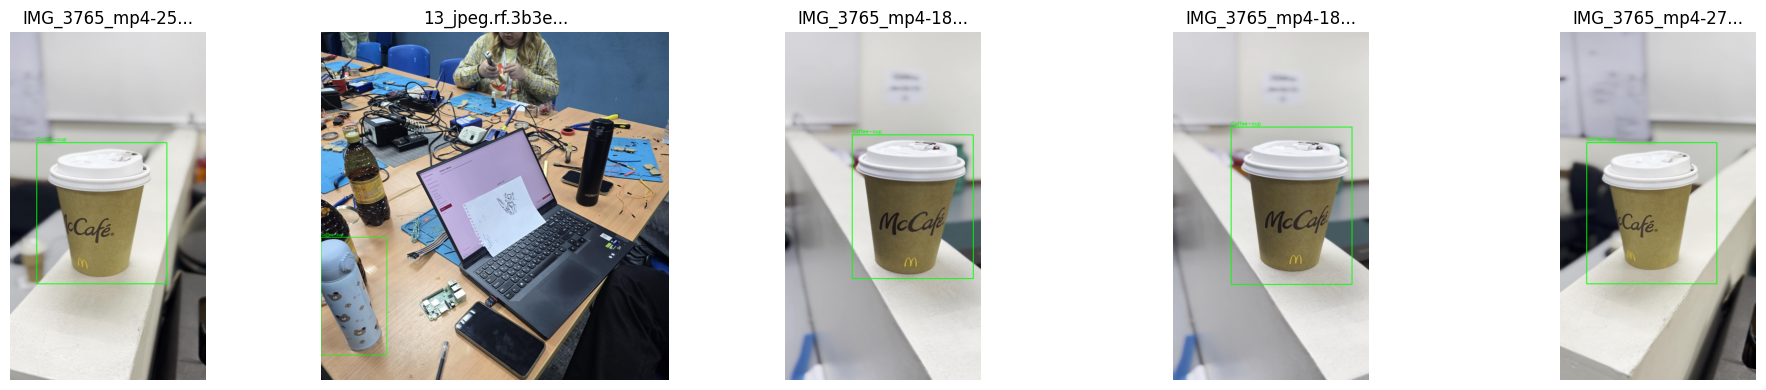

In [7]:
import os
import cv2
import glob
import random
import matplotlib.pyplot as plt

DATASET_DIR = dataset.location
img_dir = glob.glob(os.path.join(DATASET_DIR, "train", "images"))[0]
label_dir = img_dir.replace("images", "labels")

all_images = glob.glob(os.path.join(img_dir, "*.jpg")) + glob.glob(os.path.join(img_dir, "*.png"))

sample_images = random.sample(all_images, 5)

fig, axes = plt.subplots(1, 5, figsize=(20, 4))

for ax, img_path in zip(axes, sample_images):
    img = cv2.imread(img_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    h, w, _ = img.shape

    base_name = os.path.splitext(os.path.basename(img_path))[0]
    label_path = os.path.join(label_dir, base_name + ".txt")

    # ПРОВЕРКА НАЛИЧИЯ РАЗМЕТКИ
    if os.path.exists(label_path) and os.path.getsize(label_path) > 0:
        with open(label_path, "r") as f:
            lines = f.readlines()
            for line in lines:
                parts = line.strip().split()
                if len(parts) == 5:
                    _, x_c, y_c, bw, bh = map(float, parts)
                    x1, y1 = int((x_c - bw/2) * w), int((y_c - bh/2) * h)
                    x2, y2 = int((x_c + bw/2) * w), int((y_c + bh/2) * h)
                    cv2.rectangle(img, (x1, y1), (x2, y2), (0, 255, 0), 3)
                    cv2.putText(img, "Coffee-cup", (x1, y1-10), cv2.FONT_HERSHEY_SIMPLEX, 0.9, (0, 255, 0), 2)
    else:
        cv2.putText(img, "NO BBOX (Background)", (20, 40), cv2.FONT_HERSHEY_SIMPLEX, 1, (255, 0, 0), 2)

    ax.imshow(img)
    ax.axis('off')
    ax.set_title(os.path.basename(img_path)[:15] + "...")

plt.tight_layout()
plt.show()

In [8]:
# Принудительно ставим совместимые версии
!pip install --upgrade --force-reinstall torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cu121
!pip install --upgrade ultralytics

Looking in indexes: https://download.pytorch.org/whl/cu121
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 780.4/780.4 MB 34.0 MB/s  0:00:16
ERROR: Could not find a version that satisfies the requirement torchaudio (from versions: none)
ERROR: No matching distribution found for torchaudio
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 11.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [ultralytics]


In [9]:
# Устанавливаем YOLO и Gradio
!pip install -q ultralytics gradio
import os
from ultralytics import YOLO
print(" Библиотеки установлены")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
 Библиотеки установлены


In [10]:
import os, glob

# Если переменная DATASET_DIR потерялась после перезагрузки, ищем data.yaml
if 'DATASET_DIR' not in globals() or not os.path.exists(DATASET_DIR):
    yaml_paths = glob.glob('/content/**/data.yaml', recursive=True)
    if not yaml_paths:
        raise ValueError(" data.yaml не найден! Перезапустите ячейку со скачиванием датасета из Roboflow.")
    DATASET_DIR = os.path.dirname(yaml_paths[0])

YAML_PATH = os.path.join(DATASET_DIR, 'data.yaml')
print(f"Используем датасет: {YAML_PATH}")


print(f"\n Обучение завершено! Веса сохранены в: {results.save_dir}/weights/best.pt")

Используем датасет: /content/Coffee-cup-3/data.yaml
Ultralytics 8.4.199 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/Coffee-cup-3/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=coffee_

In [11]:
import gradio as gr
from PIL import Image
import os, glob

# Находим файл с лучшими весами
BEST_WEIGHTS = glob.glob('/content/runs/coffee_model*/weights/best.pt')[0]
print(f" Используем веса: {BEST_WEIGHTS}")

# Загружаем обученную модель

def predict_coffee(image):
    if image is None:
        return None
    # Предсказание с порогом уверенности 0.4

    # Метод plot() возвращает картинку с рамками (BGR формат)


    # Конвертируем BGR в RGB для корректного отображения в Gradio
    return Image.fromarray(annotated_img[:, :, ::-1])

# Создаем интерфейс



 Используем веса: /content/runs/coffee_model/weights/best.pt
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://2b981353283d424336.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
from google.colab import files
import glob

# Ищем наш лучший файл весов (обычно он в папке runs)
best_weights = glob.glob('/content/runs/coffee_model*/weights/best.pt')[0]

# Скачиваем на компьютер
files.download(best_weights)